# 01 – Task 3 analysis: robustness of phishing detectors to LLM paraphrasing

**Run this notebook only after the experiment** (`docs/task3_runbook.md`, steps 1–7). It reads the real outputs `results/metrics*.csv` and `results/predictions*.csv`; it refuses to run on the 10-row sample.

**Question (RQ1).** How much does recall at FPR = 1 % drop when the same phishing e-mails are paraphrased by an LLM? **RQ3.** Does training on paraphrases restore recall without raising FPR?

**Pipeline.** results → checks → outlier flag (kept) → aggregation over seeds with bootstrap CI → paired tests → mathematical model vs measurement → figures.

**Design.** Paired: the same test phishing e-mails in original and paraphrased form, same detector, threshold fixed on validation ham of the *original* data. Unit of replication for CIs = seed (5 seeds).

## 0.1 Domain model and formulas (summary; full version in `docs/domain_model.md`)

**Threat model (STRIDE) of the mail gateway.** The threat tested here is **T2b, Tampering / evasion**: an attacker rewrites a phishing text with an LLM so that a text detector scores it lower.

| ID | STRIDE | Threat | Component | Mitigation |
|---|---|---|---|---|
| T1 | Spoofing | Sender or brand impersonation | Mail gateway | SPF/DKIM/DMARC, content detector |
| T2a | Tampering | Training-data poisoning | Corpora | Dedupe, source audit |
| **T2b** | **Tampering** | **Evasion by LLM paraphrase** | **Detector** | **Threshold fixed on original data; augmentation (RQ3)** |
| T3 | Repudiation | No trace of model / threshold / data | Pipeline | Seeds, pins, config in git |
| T4 | Information disclosure | Private mail leaks | Corpora, weights | Public corpora only |
| T5 | Denial of service | Very long texts, alert flood | Detector | Truncation, FPR guardrail |
| T6 | Elevation of privilege | Compromised model supply chain | Weights, packages | Version pins |

**Metric.** Recall at a fixed false-positive rate: the threshold $t$ is the score exceeded by 1 % of validation ham, $\mathrm{FPR}(t)=0.01$; then $\mathrm{recall}=P(s>t)$ on phishing.

**Mathematical model (location shift).** Original phishing scores $s\sim\mathcal N(\mu,\sigma^2)$, so

$$\mathrm{recall}_{orig}=1-\Phi\left(\frac{t-\mu}{\sigma}\right).$$

Paraphrasing shifts the score by $\delta=\overline{s_{para}-s_{orig}}$ (paired mean) and keeps $\sigma$:

$$\mathrm{recall}_{para}=1-\Phi\left(\frac{t-\mu-\delta}{\sigma}\right),\qquad \delta^*(d)=(t-\mu)-\sigma\,\Phi^{-1}\bigl(1-(\mathrm{recall}_{orig}-d)\bigr).$$

$\delta^*(d)$ is the shift that costs $d$ percentage points of recall. The prediction is **not fitted** to the paraphrased recall (section 5).

**Paired test.** Exact McNemar on the discordant pairs ($b$ = detected→missed, $c$ = missed→detected), one-sided $H_1: b>c$; when $b=0$ the one-sided 95 % upper bound of the lost share is $1-0.05^{1/n}$.

In [1]:
import sys, random
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import process_data as pdx
import signal_model as sm
import visualize as viz

SEED = 42
random.seed(SEED); np.random.seed(SEED)
cfg = pdx.load_cfg()
RES, PROC, FIG = ROOT / cfg["paths"]["results"], ROOT / cfg["paths"]["processed"], ROOT / "reports" / "figures"
PROC.mkdir(parents=True, exist_ok=True)
print("seeds in config:", cfg["seeds"], "| target FPR:", cfg["target_fpr"], "| bootstrap:", pdx.N_BOOT)

seeds in config: [42, 43, 44, 45, 46] | target FPR: 0.01 | bootstrap: 10000


## 1. Load results and check that this is a real run
A toy run (the 10-row sample) must never be analysed: the checks below stop the notebook.

In [2]:
metrics = pdx.read_all(RES, "metrics")
pred = pdx.read_all(RES, "predictions")
n_seeds = metrics.groupby(["model", "condition"]).seed.nunique().min()
n_ph = int(metrics.n_phish.min()); n_ham = int(metrics.n_ham.min())
print(f"rows: metrics={len(metrics)}, predictions={len(pred)} | seeds per cell={n_seeds} | matched phishing={n_ph} | test ham={n_ham}")
assert n_seeds >= 2, "need >= 2 seeds (python scripts/04_train_eval.py --seeds 42 43 44 45 46)"
assert n_ph >= 30, "need >= 30 matched phishing e-mails: this looks like the sample run, run the full experiment"
display(metrics.groupby(["model", "condition", "version"]).size().unstack())
emails = PROC / "emails.csv"
if emails.exists():
    e = pd.read_csv(emails)
    print("Cleaned corpus (data hygiene, MP-1):")
    display(e.groupby(["split", "label", "source"]).size().unstack("split").fillna(0).astype(int))
paraf = PROC / "paraphrases.csv"
if paraf.exists():
    q = pd.read_csv(paraf)
    print(f"Paraphrase quality filter (MP-4): accepted {int(q.ok.sum())} of {len(q)} ({100*q.ok.mean():.1f} %), backend: {q.backend.unique().tolist()}")

rows: metrics=10, predictions=970 | seeds per cell=5 | matched phishing=97 | test ham=2231
Cleaned corpus (data hygiene, MP-1):
Paraphrase quality filter (MP-4): accepted 97 of 97 (100.0 %), backend: ['claude-manual']


,version,original,paraphrased
model,condition,,
tfidf_lr,baseline,5,5


,split,test,train,val
label,source,,,
0,ceas08_ham,2231,10405,2229
1,phishing_pot,246,1147,246


## 2. Outliers: flag, do not delete
The score margin (`score − threshold`) of every phishing e-mail is flagged with Tukey's 1.5·IQR rule within model × condition × version. Rows stay in the file (`is_outlier`); all statistics below are computed per seed on rates, which are robust to single extreme scores.

In [3]:
flagged = pdx.flag_outliers(pred, metrics)
share = flagged.groupby(["model", "condition", "version"]).is_outlier.mean().mul(100).round(2)
display(share.unstack("version"))
print("Flagged: %d of %d (%.2f %%), all retained" % (flagged.is_outlier.sum(), len(flagged), 100 * flagged.is_outlier.mean()))

Flagged: 25 of 970 (2.58 %), all retained


,version,original,paraphrased
model,condition,,
tfidf_lr,baseline,2.06,3.09


## 3. Aggregation over seeds and guardrail
Mean, SD, median, IQR and a 95 % percentile bootstrap CI over the seeds (10 000 resamples). Guardrail fixed in `docs/methodology_card.md`: realised FPR ≤ 2 %. FPR is reported, never filtered out.

In [4]:
rng = np.random.default_rng(SEED)
summary = pdx.summarise(metrics, rng)
delta = pdx.paired_delta(metrics, rng)
summary.to_csv(PROC / "metrics_summary.csv", index=False)
delta.to_csv(PROC / "paired_delta.csv", index=False)
flagged.to_csv(PROC / "predictions_flagged.csv", index=False)
cols = ["model", "condition", "version", "n_seeds", "recall_mean", "recall_ci_lo", "recall_ci_hi", "recall_sd", "fpr_mean", "f1_mean", "roc_auc_mean", "fpr_guardrail_ok"]
display(summary[cols].round(3))
print("Guardrail (realised FPR <= 2 % in every cell):", "PASSED" if summary.fpr_guardrail_ok.all() else "FAILED")

Guardrail (realised FPR <= 2 % in every cell): PASSED


,model,condition,version,n_seeds,recall_mean,recall_ci_lo,recall_ci_hi,recall_sd,fpr_mean,f1_mean,roc_auc_mean,fpr_guardrail_ok
0,tfidf_lr,baseline,original,5,0.979,0.979,0.979,0.0,0.005,0.936,1.0,True
1,tfidf_lr,baseline,paraphrased,5,0.979,0.979,0.979,0.0,0.005,0.936,1.0,True


## 4. Paired effect of paraphrasing
Change of recall (paraphrased − original) per seed, mean and bootstrap CI over seeds. Negative = paraphrasing helps the attacker.

In [5]:
display(delta.round(4))

,model,condition,n_seeds,delta_recall_mean,delta_ci_lo,delta_ci_hi
0,tfidf_lr,baseline,5,0.0,0.0,0.0


### 4.1 Hypothesis tests (RQ1, RQ3)
`scripts/05_stats.py` runs the exact McNemar test on the paired detections (one-sided, H1: detection drops), Holm correction across detectors, and the RQ3 criterion (augmented recall within 2 p.p. of baseline, FPR rise ≤ 1 p.p.). Run it once before this cell.

In [6]:
sfile = RES / "summary.csv"
if sfile.exists():
    display(pd.read_csv(sfile).round(4))
    print((RES / "summary.md").read_text().split("## RQ3")[-1] if (RES / "summary.md").exists() else "")
else:
    print("results/summary.csv missing: run  python scripts/05_stats.py")

# Results summary

## RQ1 (paired, one-sided, Holm-adjusted across detectors)

| model    |   n_pairs |   recall_orig |   recall_para |   delta |   ci_low |   ci_high |   b |   c |   p_one_sided |   delta_sd_over_seeds |   p_holm | reject_H0_RQ1   |
|:---------|----------:|--------------:|--------------:|--------:|---------:|----------:|----:|----:|--------------:|----------------------:|---------:|:----------------|
| tfidf_lr |        97 |        0.9794 |        0.9794 |       0 |        0 |         0 |   0 |   0 |             1 |                     0 |        1 | False           |

## RQ2

skipped: statsmodels not installed


,model,n_pairs,recall_orig,recall_para,delta,ci_low,ci_high,b,c,p_one_sided,delta_sd_over_seeds,p_holm,reject_H0_RQ1
0,tfidf_lr,97,0.9794,0.9794,0.0,0.0,0.0,0,0,1.0,0.0,1.0,False


## 5. Mathematical model vs measurement
`src/signal_model.py` (derivation in `docs/domain_model.md`, section 5): scores of original phishing ~ N(μ, σ²); paraphrasing = pure location shift δ (mean paired difference). The predicted recall after paraphrasing uses only μ, σ, δ and the threshold; it is **not fitted** to the paraphrased recall. Large errors or a spread ratio far from 1 mean the assumption fails for that detector (for example saturated probabilities of a transformer).

In [7]:
cells = sm.check_cells(flagged)
cells.to_csv(PROC / "model_check_cells.csv", index=False)
check = sm.summarise_check(cells)
check.to_csv(PROC / "model_check.csv", index=False)
display(check.round(3))
print("Largest model error: %.1f p.p." % check.abs_error_pp.max())

Largest model error: 1.2 p.p.


,model,condition,recall_orig_measured,recall_orig_model,recall_para_measured,recall_para_model,abs_error_pp,delta,delta_ci_lo,delta_ci_hi,median_margin_orig,sigma_ratio_para_orig,breakeven_shift_2pp
0,tfidf_lr,baseline,0.979,0.997,0.979,0.992,1.218,-0.53,-0.67,-0.39,4.272,0.98,-1.101


## 6. Figures
Rules: (1) labelled axes with units, rates start at 0; (2) variance shown: 95 % CI error bars over seeds, box + individual e-mails; (3) colour-blind-safe palette plus markers and line styles. Saved as vector `.pdf` and 300 DPI `.png`.

wrote /home/claude/work/t3run/reports/figures/fig1_recall_original_vs_paraphrased.pdf and .png


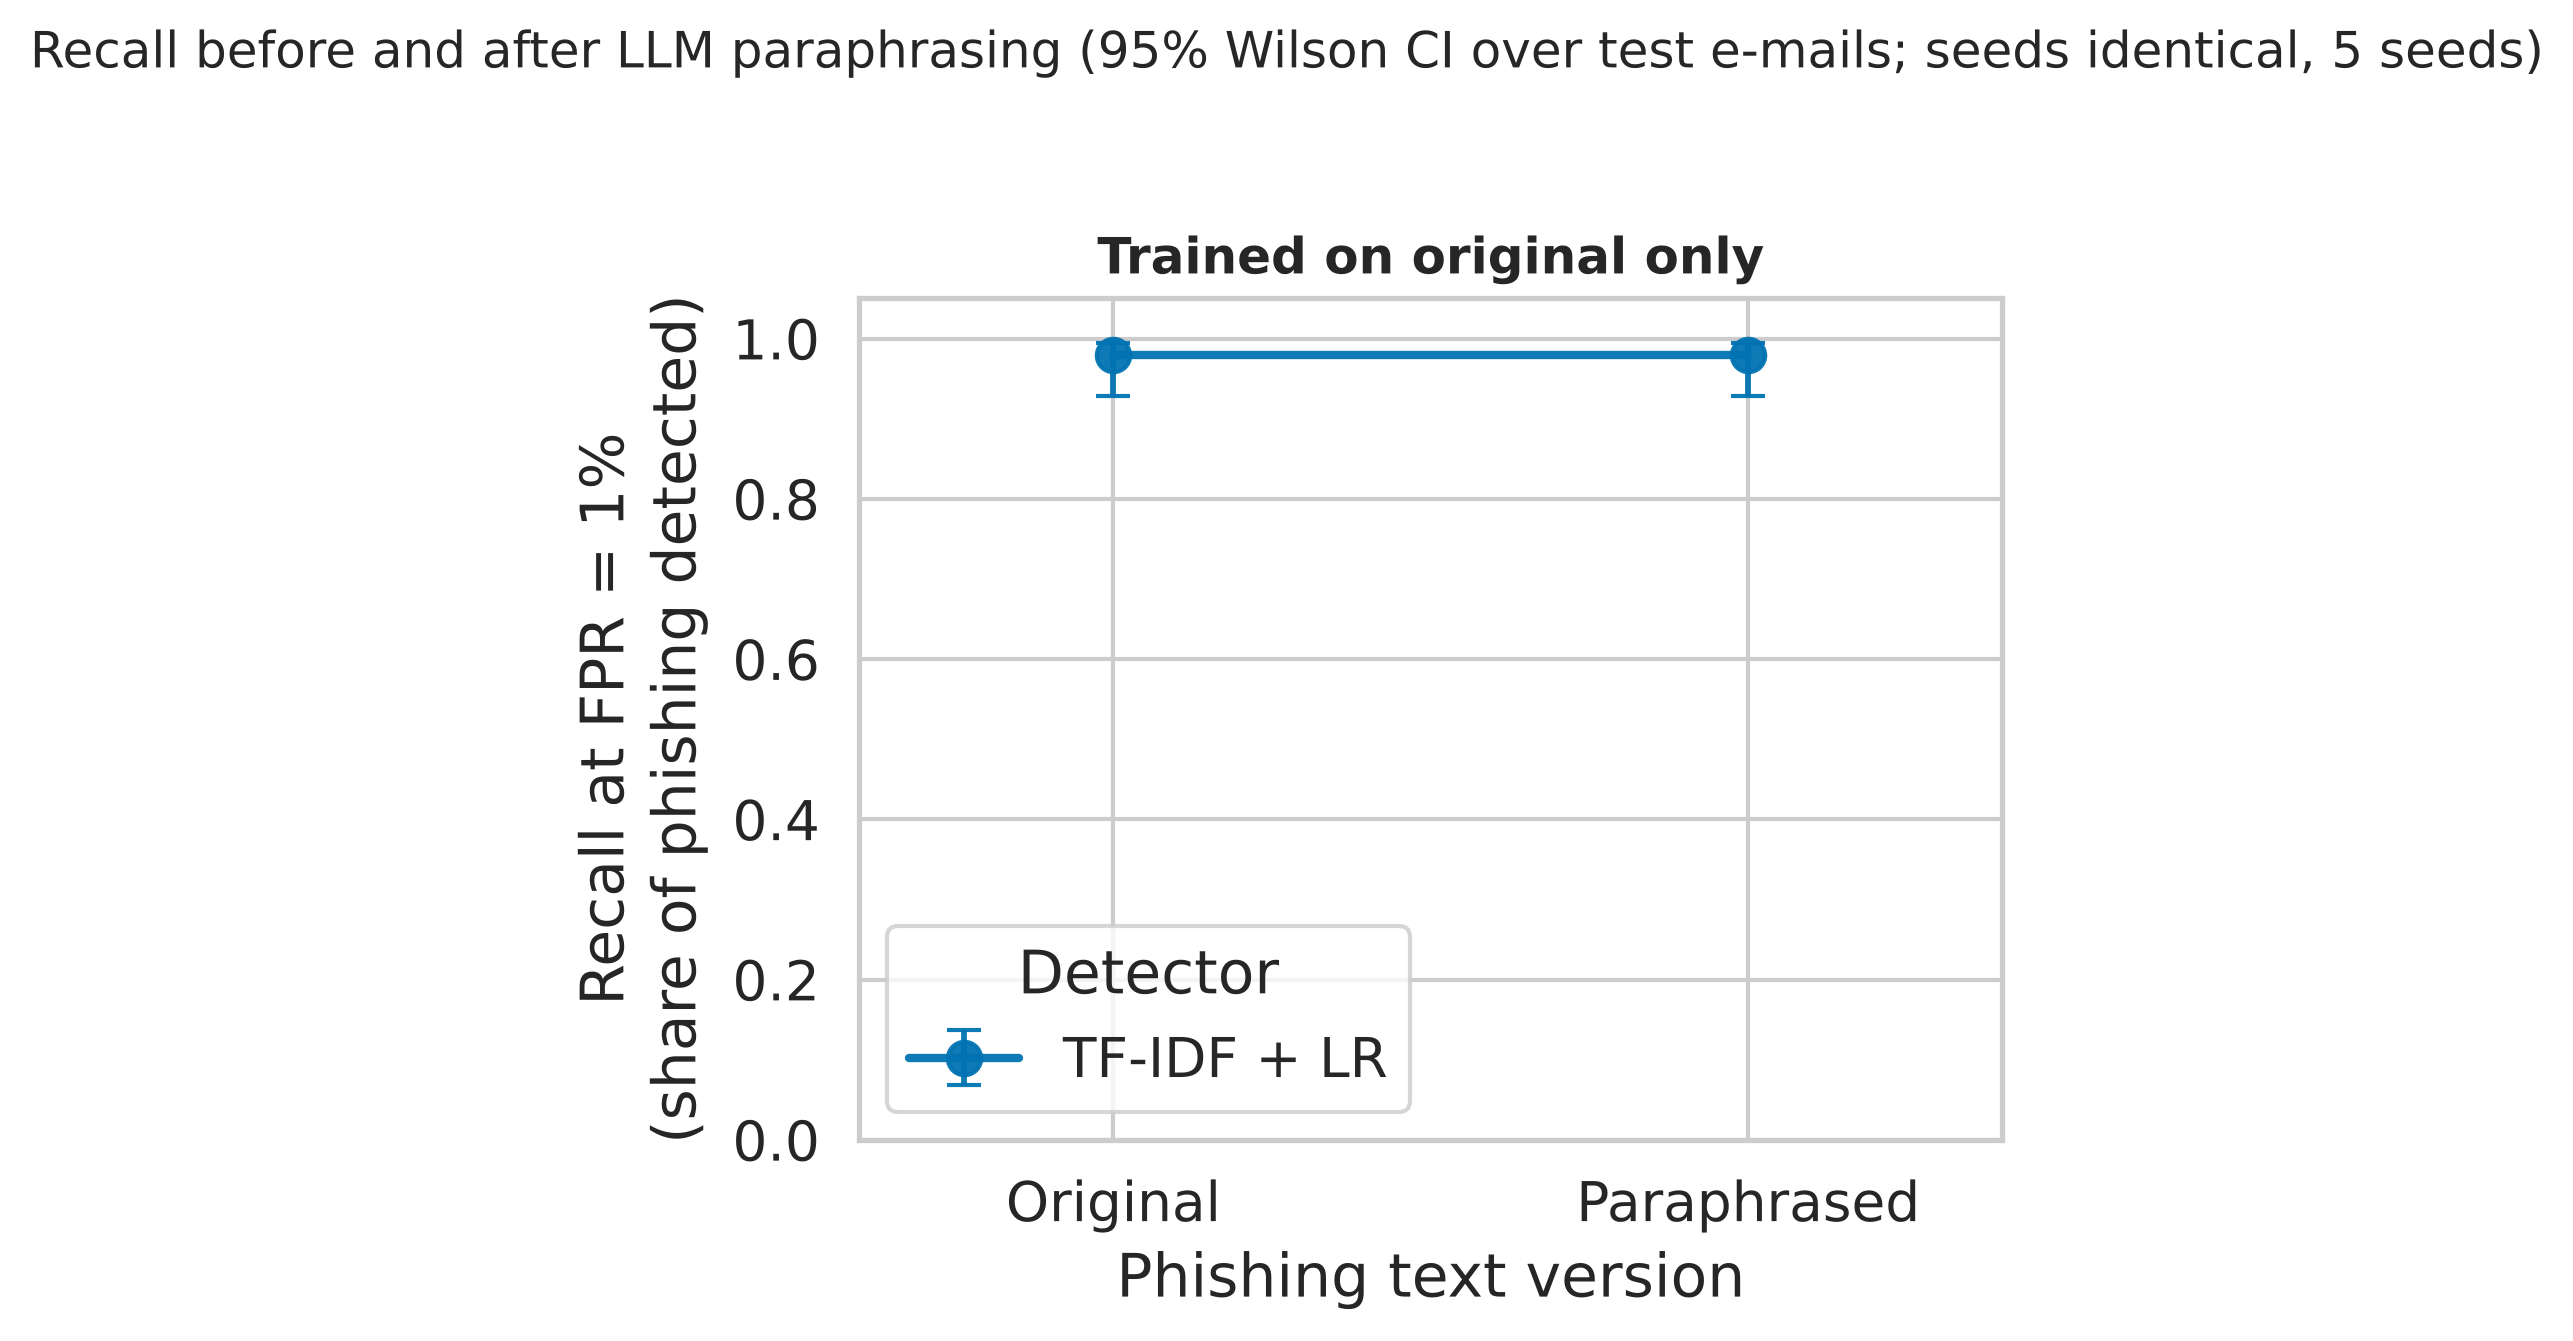

In [8]:
viz.set_style()
viz.fig_recall(summary, cfg["target_fpr"], FIG)
from IPython.display import Image; display(Image(filename=str(FIG / "fig1_recall_original_vs_paraphrased.png")))

wrote /home/claude/work/t3run/reports/figures/fig2_score_margin_distribution.pdf and .png


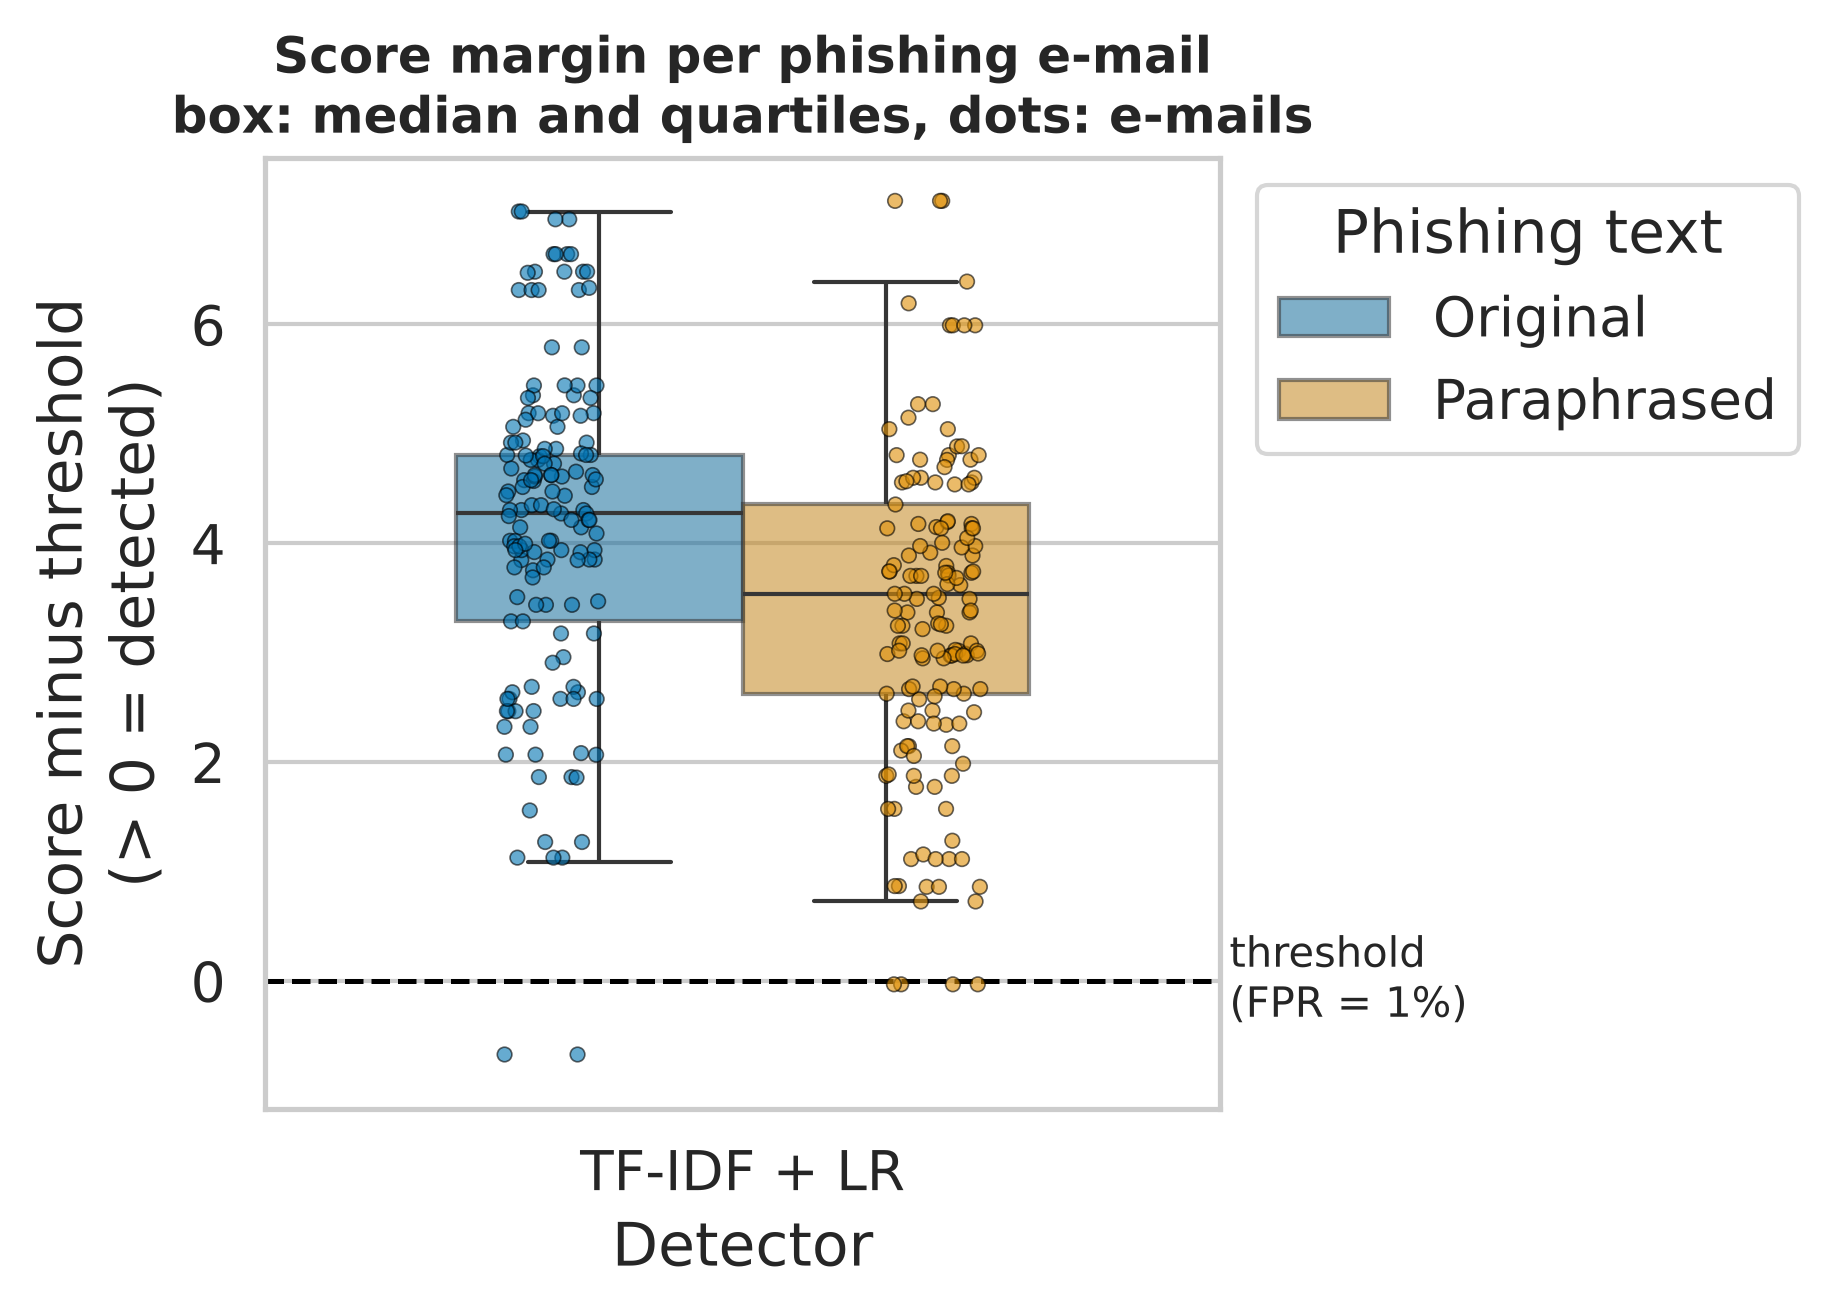

In [9]:
viz.fig_margin(flagged, FIG)
display(Image(filename=str(FIG / "fig2_score_margin_distribution.png")))

wrote /home/claude/work/t3run/reports/figures/fig3_model_check.pdf and .png


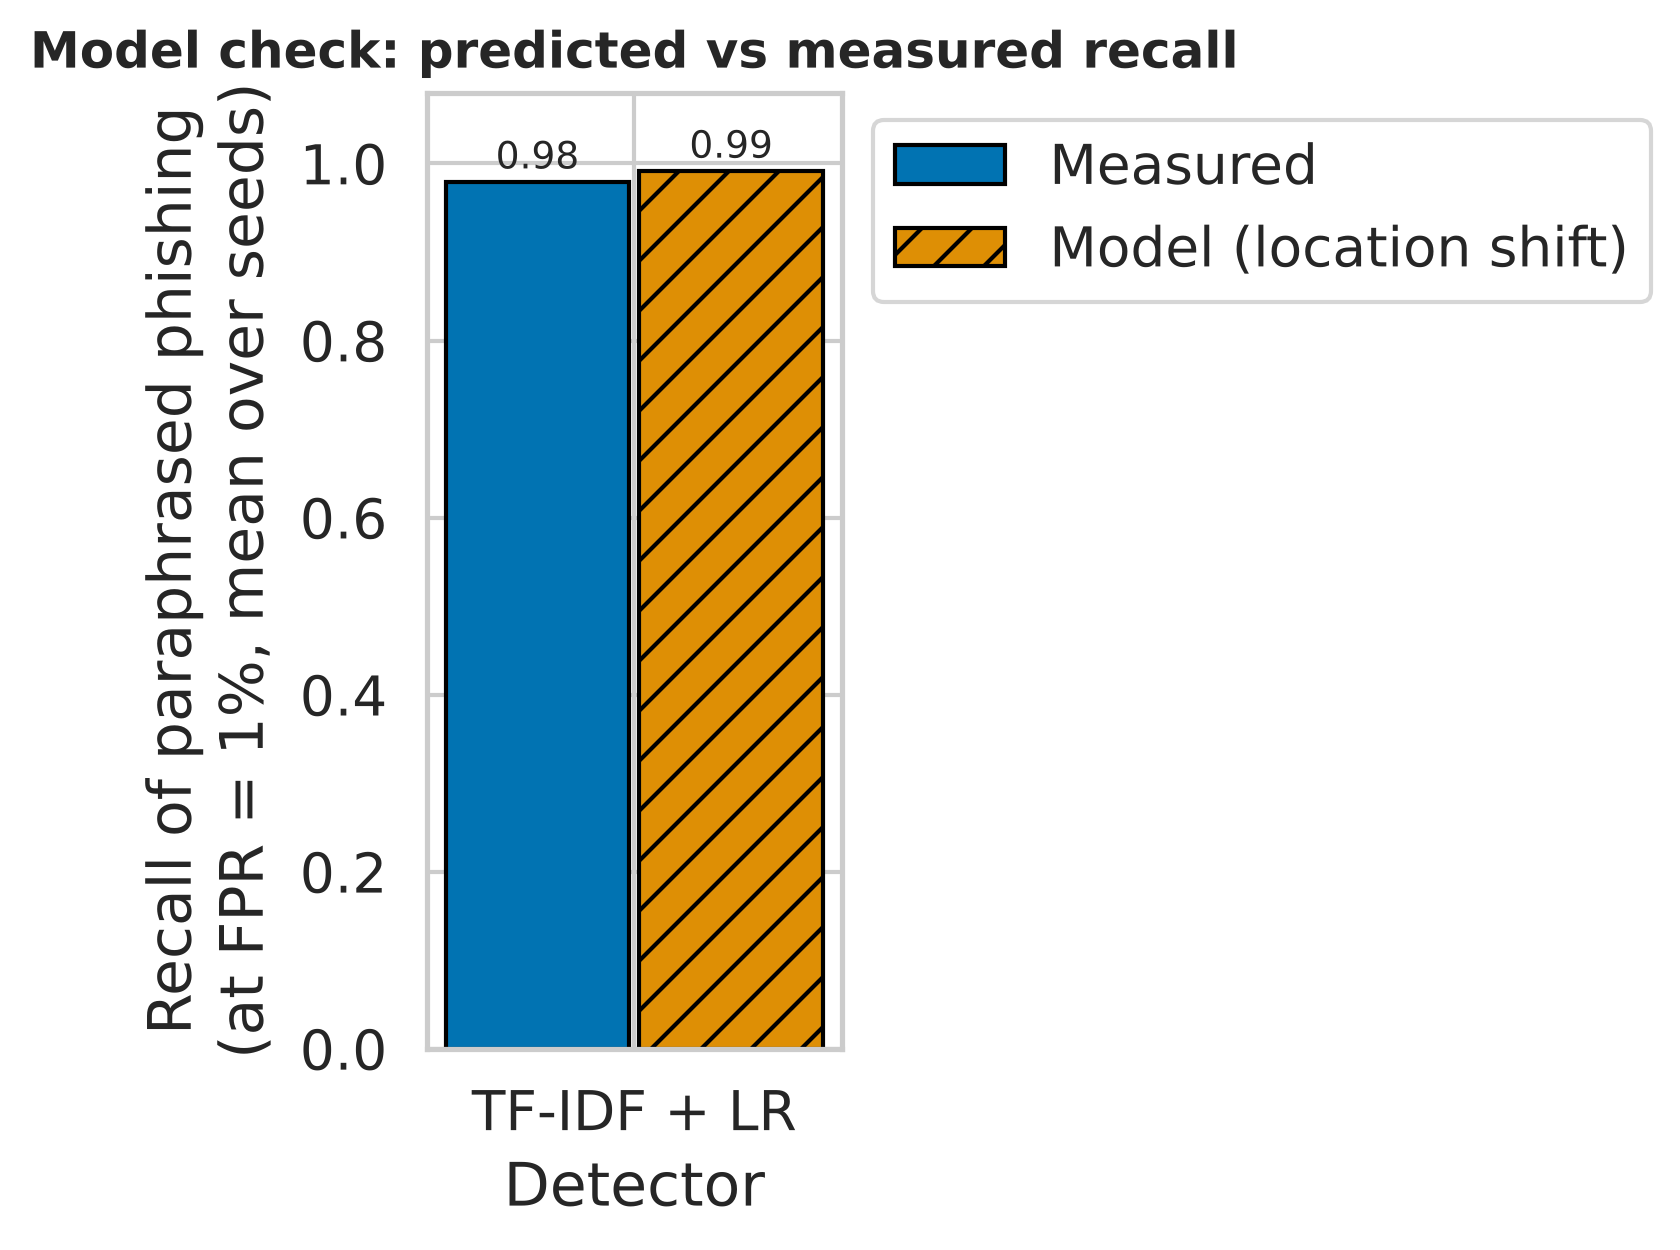

In [10]:
viz.fig_model_check(check, FIG)
display(Image(filename=str(FIG / "fig3_model_check.png")))

## 7. Conclusions (computed from the numbers above)

In [11]:
base = summary[summary.condition == "baseline"]
for m in dict.fromkeys(base.model):
    r = base[base.model == m].set_index("version"); d = delta[(delta.model == m) & (delta.condition == "baseline")].iloc[0]
    print(f"{viz.nice(m)}: recall {r.loc['original','recall_mean']:.3f} -> {r.loc['paraphrased','recall_mean']:.3f} "
          f"(change {d.delta_recall_mean*100:+.1f} p.p., 95% CI over seeds [{d.delta_ci_lo*100:+.1f}, {d.delta_ci_hi*100:+.1f}])")
if (summary.condition == "augmented").any():
    for m in dict.fromkeys(summary.model):
        a = summary[(summary.model == m) & (summary.condition == "augmented") & (summary.version == "paraphrased")]
        b = base[(base.model == m) & (base.version == "paraphrased")]
        if len(a) and len(b):
            print(f"{viz.nice(m)} with augmentation: recall on paraphrased {b.recall_mean.iloc[0]:.3f} -> {a.recall_mean.iloc[0]:.3f}, FPR {b.fpr_mean.iloc[0]*100:.2f} % -> {a.fpr_mean.iloc[0]*100:.2f} %")
if (summary.recall_sd.fillna(0) < 1e-9).all():
    print("Note: the detector is deterministic, so the seeds give identical numbers; uncertainty comes from the paired test and the score-shift interval, not from seeds.")
print("Caveats and deviations of this run (paraphraser, detectors, data, ceiling effect): docs/run_notes.md")

TF-IDF + LR: recall 0.979 -> 0.979 (change +0.0 p.p., 95% CI over seeds [+0.0, +0.0])
Note: the detector is deterministic, so the seeds give identical numbers; uncertainty comes from the paired test and the score-shift interval, not from seeds.
Caveats and deviations of this run (paraphraser, detectors, data, ceiling effect): docs/run_notes.md
